In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DRIVER_A = "Max Verstappen"
COMPARE_DRIVER = "Lewis Hamilton"  # Swap to "Lando Norris", "Charles Leclerc", etc.

df = pd.read_csv("data/store/f1_master.csv", parse_dates=["date"])
weather = pd.read_csv("data/store/weather.csv")

# Merge modern era (2018+) with FastF1 weather data
modern = df[df["season"] >= 2018].merge(
    weather[["race_id", "rain_pct", "is_wet_race", "avg_track_temp_c"]],
    on="race_id",
    how="inner",
)

# Classified finishers mask (lead lap + lapped, excludes mechanical DNFs/crashes)
modern["is_classified"] = modern["status"].str.contains(r"^Finished|^\+\d+ Lap", na=False)

# 1. List all wet races
wet_races = (
    modern[modern["is_wet_race"]]
    [["race_id", "season", "round", "race_name", "circuit_id", "rain_pct"]]
    .drop_duplicates()
    .sort_values(["season", "round"])
)
print(f"Total wet races found (2018–{modern['season'].max()}): {len(wet_races)}")
display(wet_races.tail(10))

# 2. Verstappen's average finish on those exact tracks: Wet vs. Dry
wet_circuits = wet_races["circuit_id"].unique()
ver_tracks = modern[
    (modern["full_name"] == DRIVER_A)
    & (modern["circuit_id"].isin(wet_circuits))
    & (modern["is_classified"])
]

ver_track_avg = (
    ver_tracks.groupby(["circuit_id", "is_wet_race"])["position"]
    .agg(["count", "mean"])
    .unstack("is_wet_race")
)
ver_track_avg.columns = ["dry_races", "wet_races", "dry_avg_pos", "wet_avg_pos"]
ver_track_avg = (
    ver_track_avg.dropna(subset=["wet_avg_pos"])
    .assign(wet_advantage=lambda d: (d["dry_avg_pos"] - d["wet_avg_pos"]).round(2))  # + = better in wet
    .round(2)
    .sort_values("wet_advantage", ascending=False)
)

print(f"\n=== {DRIVER_A}: Track-by-Track Average Finish (Wet vs. Dry on Rain Circuits) ===")
print(f"Overall Wet Avg Finish: P{ver_tracks[ver_tracks['is_wet_race']]['position'].mean():.2f}")
print(f"Overall Dry Avg Finish (same tracks): P{ver_tracks[~ver_tracks['is_wet_race']]['position'].mean():.2f}")
display(ver_track_avg)

Total wet races found (2018–2026): 48


,race_id,season,round,race_name,circuit_id,rain_pct
2979,2025_01,2025,1,Australian Grand Prix,albert_park,32.6
3079,2025_06,2025,6,Miami Grand Prix,miami,3.4
3158,2025_10,2025,10,Canadian Grand Prix,villeneuve,0.6
3198,2025_12,2025,12,British Grand Prix,silverstone,18.1
3218,2025_13,2025,13,Belgian Grand Prix,spa,45.7
3318,2025_18,2025,18,Singapore Grand Prix,marina_bay,3.7
3524,2026_04,2026,4,Miami Grand Prix,miami,1.8
3700,2026_12,2026,12,Dutch Grand Prix,zandvoort,16.8
3788,2026_16,2026,16,Bahrain Grand Prix in Malaysia,sepang,31.5
3876,2026_20,2026,20,Brazilian Grand Prix,interlagos,4.4



=== Max Verstappen: Track-by-Track Average Finish (Wet vs. Dry on Rain Circuits) ===
Overall Wet Avg Finish: P3.02
Overall Dry Avg Finish (same tracks): P2.52


,dry_races,wet_races,dry_avg_pos,wet_avg_pos,wet_advantage
circuit_id,,,,,
suzuka,5.0,1.0,2.80,1.00,1.80
interlagos,5.0,3.0,2.80,1.33,1.47
catalunya,7.0,2.0,3.29,2.00,1.29
villeneuve,5.0,2.0,2.60,1.50,1.10
spa,5.0,3.0,2.80,2.00,0.80
zandvoort,4.0,1.0,1.50,1.00,0.50
imola,3.0,1.0,1.00,1.00,0.00
ricard,3.0,1.0,2.00,2.00,0.00
hungaroring,5.0,3.0,3.80,4.00,-0.20


=== RED BULL CAR STRENGTH BY SEASON ===


,season,team_pts,team_wins,car_avg_pos,car_strength_pct
5,2018,419.0,4,3.70,64.0
16,2019,417.0,3,5.11,56.4
27,2020,319.0,2,5.19,55.7
38,2021,578.5,11,4.00,95.7
48,2022,724.0,17,2.59,100.0
58,2023,790.0,21,2.49,100.0
67,2024,537.0,9,4.23,88.2
77,2025,410.0,8,6.36,52.9
89,2026,395.0,3,4.91,67.3


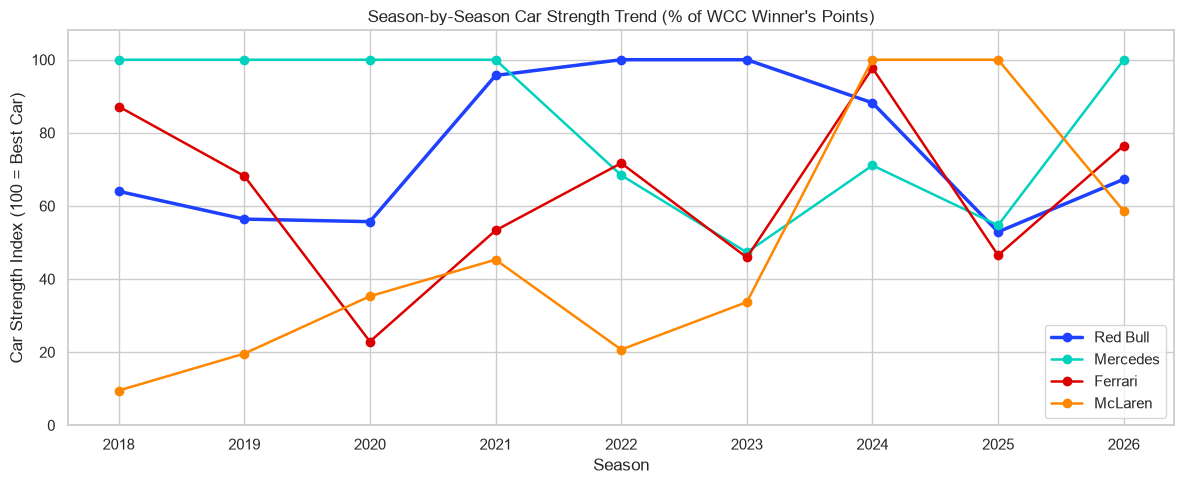

In [2]:
# Season-by-season constructor performance
team_season = (
    modern.groupby(["season", "constructor_id", "constructor_name"], as_index=False)
    .agg(
        team_pts=("points", "sum"),
        team_wins=("is_win", "sum"),
        car_avg_pos=("position", lambda s: s[modern.loc[s.index, "is_classified"]].mean()),
    )
)

# Normalize points relative to that season's WCC winner (100 = best car)
wcc_pts = team_season.groupby("season")["team_pts"].transform("max")
team_season["car_strength_pct"] = (team_season["team_pts"] / wcc_pts * 100).round(1)
team_season["car_avg_pos"] = team_season["car_avg_pos"].round(2)

# Highlight Red Bull's season-by-season car strength
rb_trend = team_season[team_season["constructor_id"] == "red_bull"].sort_values("season")
print("=== RED BULL CAR STRENGTH BY SEASON ===")
display(rb_trend[["season", "team_pts", "team_wins", "car_avg_pos", "car_strength_pct"]])

# Plot top 4 constructors' car strength trend (2018–present)
top_teams = ["red_bull", "mercedes", "ferrari", "mclaren"]
team_colors = {
    "red_bull": "#1E41FF",
    "mercedes": "#00D2BE",
    "ferrari": "#DC0000",
    "mclaren": "#FF8700",
}

fig, ax = plt.subplots(figsize=(12, 5))
for cid in top_teams:
    sub = team_season[team_season["constructor_id"] == cid].sort_values("season")
    if not sub.empty:
        ax.plot(
            sub["season"],
            sub["car_strength_pct"],
            marker="o",
            linewidth=2.5 if cid == "red_bull" else 1.8,
            label=sub["constructor_name"].iloc[-1],
            color=team_colors.get(cid),
        )

ax.set_title("Season-by-Season Car Strength Trend (% of WCC Winner's Points)")
ax.set_xlabel("Season")
ax.set_ylabel("Car Strength Index (100 = Best Car)")
ax.set_ylim(0, 108)
ax.legend()
plt.tight_layout()
plt.show()

In [3]:
# Attach season car strength to every driver-race row
enriched = modern.merge(
    team_season[["season", "constructor_id", "car_strength_pct", "car_avg_pos"]],
    on=["season", "constructor_id"],
    how="left",
)

def get_driver_wet_relative(driver_name: str) -> pd.DataFrame:
    sub = enriched[(enriched["full_name"] == driver_name) & (enriched["is_classified"])]
    wet = (
        sub[sub["is_wet_race"]]
        .groupby(["season", "constructor_name", "car_strength_pct", "car_avg_pos"], as_index=False)
        .agg(
            wet_races=("race_id", "count"),
            wet_wins=("is_win", "sum"),
            wet_avg_pos=("position", "mean"),
            wet_avg_grid=("grid", "mean"),
        )
    )
    dry = (
        sub[~sub["is_wet_race"]]
        .groupby("season", as_index=False)["position"]
        .mean()
        .rename(columns={"position": "dry_avg_pos"})
    )
    out = wet.merge(dry, on="season", how="left")
    # Positive = finished better in the wet than the car's season average / own dry average
    out["wet_vs_car_delta"] = (out["car_avg_pos"] - out["wet_avg_pos"]).round(2)
    out["wet_vs_dry_delta"] = (out["dry_avg_pos"] - out["wet_avg_pos"]).round(2)
    out["wet_pos_gained"] = (out["wet_avg_grid"] - out["wet_avg_pos"]).round(2)
    out["driver"] = driver_name
    return out.sort_values("season")

df_a = get_driver_wet_relative(DRIVER_A)
df_b = get_driver_wet_relative(COMPARE_DRIVER)

# Side-by-side summary table
summary = pd.DataFrame([
    {
        "Driver": d_name,
        "Wet Starts (Classified)": int(d["wet_races"].sum()),
        "Wet Wins": int(d["wet_wins"].sum()),
        "Avg Car Strength (Wet Seasons)": round(d["car_strength_pct"].mean(), 1),
        "Avg Wet Finish": round(d["wet_avg_pos"].mean(), 2),
        "Avg Dry Finish": round(d["dry_avg_pos"].mean(), 2),
        "Wet Outperformance vs Car (+ Better)": round(d["wet_vs_car_delta"].mean(), 2),
        "Avg Positions Gained in Wet": round(d["wet_pos_gained"].mean(), 2),
    }
    for d_name, d in [(DRIVER_A, df_a), (COMPARE_DRIVER, df_b)]
])
display(summary)

,Driver,Wet Starts (Classified),Wet Wins,Avg Car Strength (Wet Seasons),Avg Wet Finish,Avg Dry Finish,Wet Outperformance vs Car (+ Better),Avg Positions Gained in Wet
0,Max Verstappen,47,16,75.6,2.86,2.37,1.42,2.03
1,Lewis Hamilton,47,15,78.9,3.99,3.92,0.22,0.57


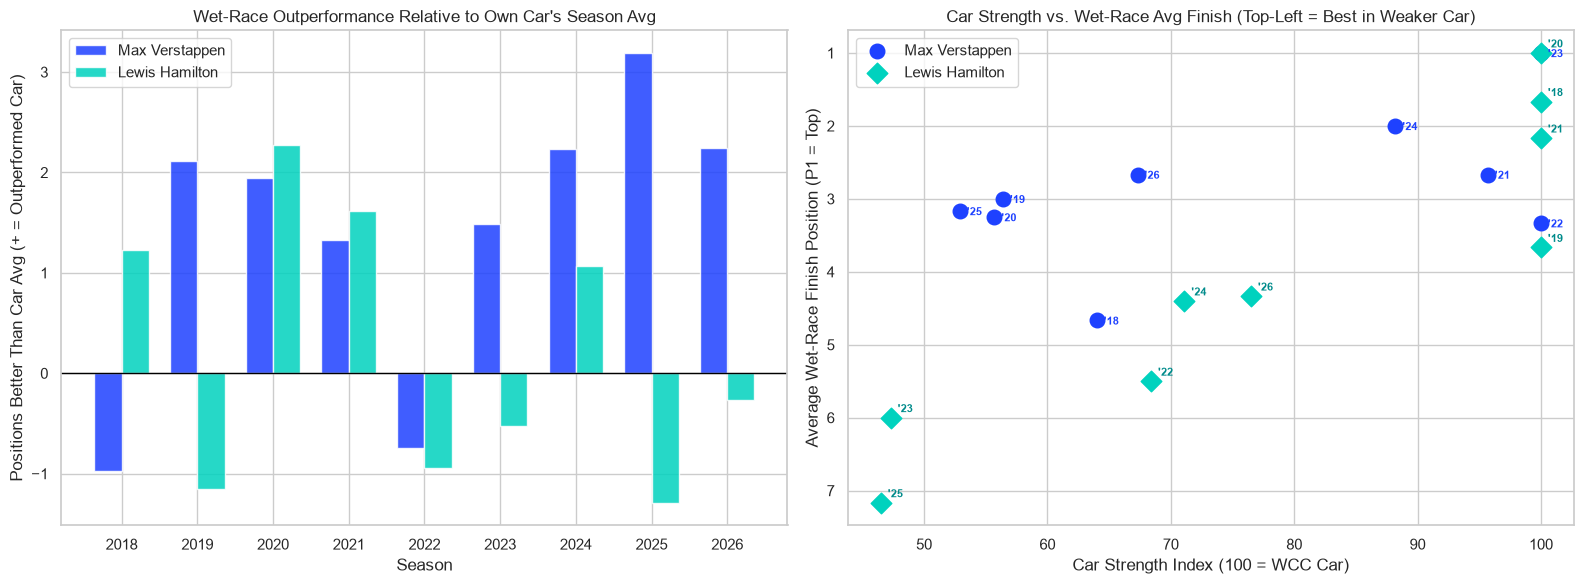

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Left Panel: Season-by-Season Relative Wet Outperformance ---
seasons = sorted(set(df_a["season"]).union(set(df_b["season"])))
x = np.arange(len(seasons))
w = 0.36

a_vals = [df_a.loc[df_a["season"] == s, "wet_vs_car_delta"].values[0] if s in df_a["season"].values else np.nan for s in seasons]
b_vals = [df_b.loc[df_b["season"] == s, "wet_vs_car_delta"].values[0] if s in df_b["season"].values else np.nan for s in seasons]

axes[0].bar(x - w / 2, a_vals, width=w, color="#1E41FF", alpha=0.85, label=DRIVER_A)
axes[0].bar(x + w / 2, b_vals, width=w, color="#00D2BE", alpha=0.85, label=COMPARE_DRIVER)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xticks(x)
axes[0].set_xticklabels(seasons)
axes[0].set_title("Wet-Race Outperformance Relative to Own Car's Season Avg")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Positions Better Than Car Avg (+ = Outperformed Car)")
axes[0].legend()

# --- Right Panel: Car Strength vs. Wet Avg Finish ---
axes[1].scatter(df_a["car_strength_pct"], df_a["wet_avg_pos"], s=110, color="#1E41FF", label=DRIVER_A, zorder=3)
axes[1].scatter(df_b["car_strength_pct"], df_b["wet_avg_pos"], s=110, color="#00D2BE", marker="D", label=COMPARE_DRIVER, zorder=3)

for _, r in df_a.iterrows():
    axes[1].annotate(f"'{str(int(r['season']))[2:]}", (r["car_strength_pct"], r["wet_avg_pos"]), xytext=(5, -3), textcoords="offset points", fontsize=8, color="#1E41FF", fontweight="bold")
for _, r in df_b.iterrows():
    axes[1].annotate(f"'{str(int(r['season']))[2:]}", (r["car_strength_pct"], r["wet_avg_pos"]), xytext=(5, 4), textcoords="offset points", fontsize=8, color="#008B8B", fontweight="bold")

axes[1].invert_yaxis()  # P1 at the top
axes[1].set_title("Car Strength vs. Wet-Race Avg Finish (Top-Left = Best in Weaker Car)")
axes[1].set_xlabel("Car Strength Index (100 = WCC Car)")
axes[1].set_ylabel("Average Wet-Race Finish Position (P1 = Top)")
axes[1].legend()

plt.tight_layout()
plt.show()